#### Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path



#### Data loading

In [4]:
DATA_DIR = Path(".")
ratings = pd.read_csv(
    DATA_DIR / "ratings.dat",
    sep="::",
    engine="python",
    names=["user_id", "movie_id", "rating", "timestamp"]
)

movies = pd.read_csv(
    DATA_DIR / "movies.dat",
    sep="::",
    engine="python",
    names=["movie_id", "title", "genres"],encoding="latin-1"
)
users = pd.read_csv(
    DATA_DIR / "users.dat",
    sep="::",
    engine="python",
    names=["user_id", "gender", "age", "occupation", "zip_code"]
)
print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)
print("Users shape:", users.shape)

n_users = ratings["user_id"].nunique()
n_items = ratings["movie_id"].nunique()
n_interactions = len(ratings)

print("no of sers:", n_users)
print("no of items or movies:", n_items)
print("Interactions (total number of rating):", n_interactions)

Ratings shape: (1000209, 4)
Movies shape: (3883, 3)
Users shape: (6040, 5)
no of sers: 6040
no of items or movies: 3706
Interactions (total number of rating): 1000209


#### Checkin start, end date and density

In [6]:
ratings["datetime"] = pd.to_datetime(ratings["timestamp"],unit="s")
print("Start:", ratings["datetime"].min())
print("End:", ratings["datetime"].max())

possible_interactions = n_users * n_items

density = n_interactions / possible_interactions

print("\nDensity:", density)
print("Density %:", round(density * 100, 2))

Start: 2000-04-25 23:05:32
End: 2003-02-28 17:49:50

Density: 0.044683625622312845
Density %: 4.47


#### User ineraction

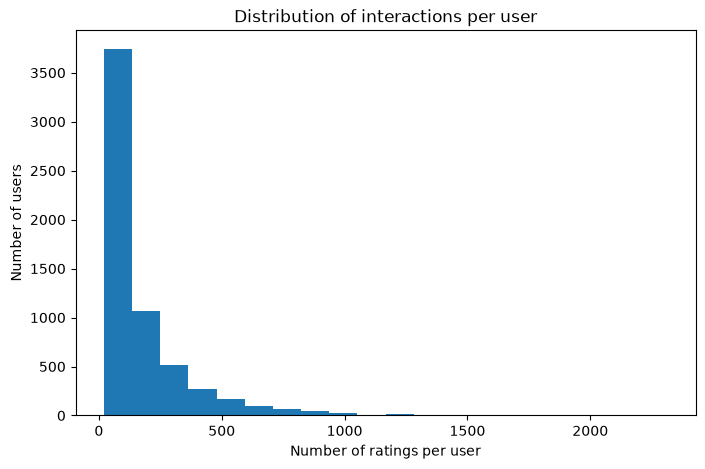

In [21]:
user_interactions = ratings.groupby("user_id").size()

plt.figure(figsize=(8, 5))
plt.hist(user_interactions.values,bins=20)
plt.xlabel("Number of ratings per user")
plt.ylabel("Number of users")
plt.title("Distribution of interactions per user")

plt.show()


#### Item interactions and long_tail distribution of movie

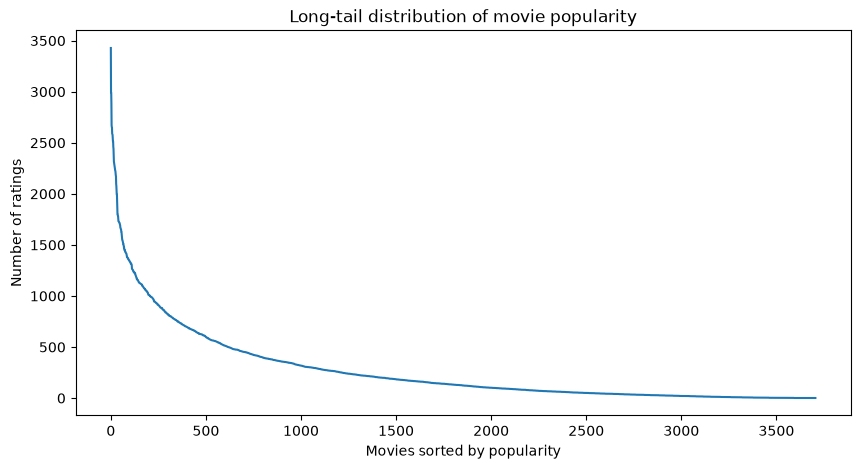

In [23]:
item_interactions = ratings.groupby("movie_id").size()
sorted_item_interactions = item_interactions.sort_values(ascending=False)
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(sorted_item_interactions)),
    sorted_item_interactions.values
)

plt.xlabel("Movies sorted by popularity")
plt.ylabel("Number of ratings")
plt.title("Long-tail distribution of movie popularity")

plt.show()

#### Rating distribution

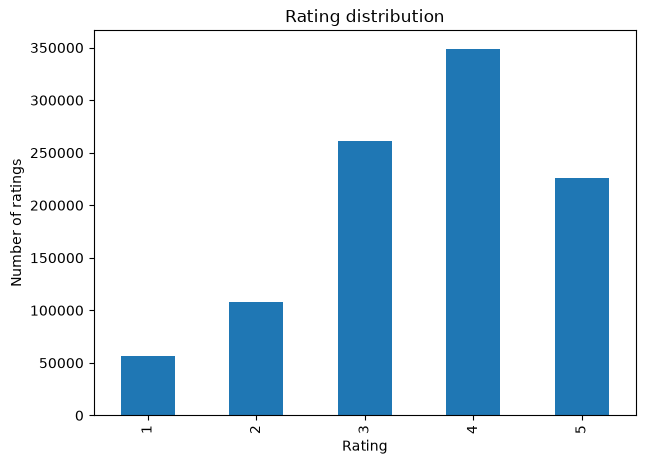

In [25]:
rating_distribution = ratings["rating"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

rating_distribution.plot(kind="bar")

plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.title("Rating distribution")

plt.show()

#### Rating percentage

rating
1     5.616226
2    10.753453
3    26.114242
4    34.889808
5    22.626271
Name: proportion, dtype: float64


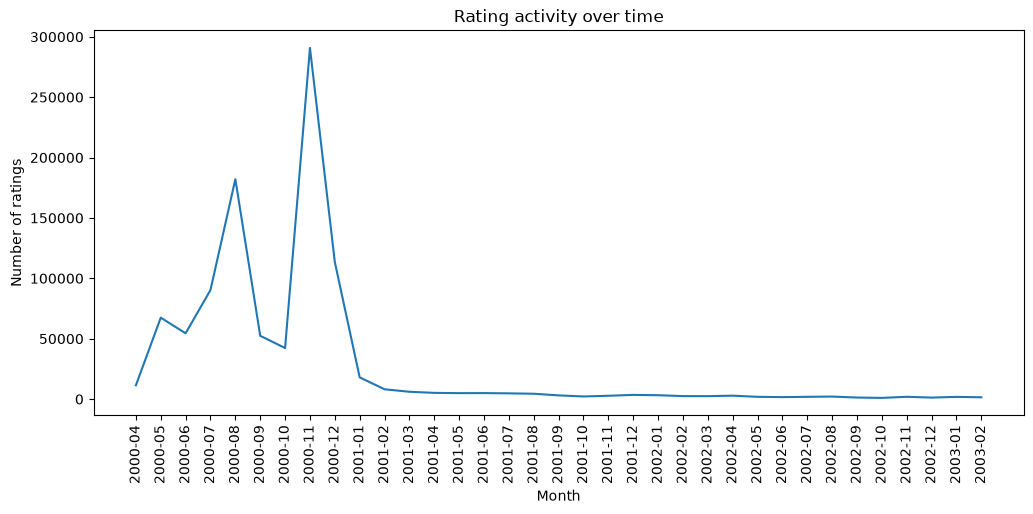

In [27]:
rating_percentage = (ratings["rating"].value_counts(normalize=True).sort_index()* 100)
print(rating_percentage)

ratings["month"] = ratings["datetime"].dt.to_period("M")

monthly_activity = ratings.groupby("month").size()

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_activity.index.astype(str),
    monthly_activity.values
)

plt.xlabel("Month")
plt.ylabel("Number of ratings")
plt.title("Rating activity over time")

plt.xticks(rotation=90)

plt.show()


#### Feedback treatment

In [28]:
POSITIVE_THRESOLD = 4
ratings['relevant']= ratings['rating']>=POSITIVE_THRESOLD
ratings["relevant"].value_counts(normalize=True) * 100

relevant
True     57.516079
False    42.483921
Name: proportion, dtype: float64

#### Cuting point


In [31]:
ratings = ratings.sort_values("timestamp").reset_index(drop=True)
train_cut = ratings["timestamp"].quantile(0.80)
val_cut = ratings["timestamp"].quantile(0.90)

train_cut_date = pd.to_datetime(train_cut, unit="s")
val_cut_date = pd.to_datetime(val_cut, unit="s")

print("Train cut:", train_cut_date)
print("Validation cut:", val_cut_date)

Train cut: 2000-12-02 14:52:18
Validation cut: 2000-12-29 23:42:56.399999976


#### Temporal split

In [36]:
train = ratings[
    ratings["timestamp"] <= train_cut
].copy()

validation = ratings[
    (ratings["timestamp"] > train_cut) &
    (ratings["timestamp"] <= val_cut)
].copy()

test = ratings[
    ratings["timestamp"] > val_cut
].copy()

print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)
total = len(ratings)

print("Train %:", round(len(train) / total * 100, 2))
print("Validation %:", round(len(validation) / total * 100, 2))
print("Test %:", round(len(test) / total * 100, 2))

print('\n Time range check')

print(
    "Train:",
    train["datetime"].min(),
    "to",
    train["datetime"].max()
)

print(
    "Validation:",
    validation["datetime"].min(),
    "to",
    validation["datetime"].max()
)

print(
    "Test:",
    test["datetime"].min(),
    "to",
    test["datetime"].max()
)

Train: (800168, 7)
Validation: (100020, 7)
Test: (100021, 7)
Train %: 80.0
Validation %: 10.0
Test %: 10.0

 Time range check
Train: 2000-04-25 23:05:32 to 2000-12-02 14:52:18
Validation: 2000-12-02 14:52:28 to 2000-12-29 23:42:47
Test: 2000-12-29 23:43:34 to 2003-02-28 17:49:50


#### User and items 

In [37]:
train_users = set(train["user_id"])
validation_users = set(validation["user_id"])
test_users = set(test["user_id"])

print(
    "Validation users unseen in train:",
    len(validation_users - train_users)
)

print(
    "Test users unseen in train:",
    len(test_users - train_users)
)

train_items = set(train["movie_id"])
validation_items = set(validation["movie_id"])
test_items = set(test["movie_id"])

print(
    "\nValidation items unseen in train:",
    len(validation_items - train_items)
)

print(
    "Test items unseen in train:",
    len(test_items - train_items)
)

Validation users unseen in train: 611
Test users unseen in train: 200

Validation items unseen in train: 16
Test items unseen in train: 33


#### Full catalogue

In [40]:
catalogue = pd.Index(movies["movie_id"].drop_duplicates(),name="movie_id")
print('catalogue_size\t', len(catalogue))
catalogue

catalogue_size	 3883


Index([   1,    2,    3,    4,    5,    6,    7,    8,    9,   10,
       ...
       3943, 3944, 3945, 3946, 3947, 3948, 3949, 3950, 3951, 3952],
      dtype='int64', name='movie_id', length=3883)

#### Most popular variant A (all popular movie)

In [41]:
popular_all= (train.groupby('movie_id').size()
    .reindex(catalogue,fill_value=0).sort_values(ascending= False))
popular_all.head(10)
# giving 0 for non rated movie for movie train period


movie_id
2858    2902
260     2516
1196    2516
1210    2457
589     2284
2028    2245
480     2234
1270    2184
2571    2172
1580    2157
dtype: int64

#### Number of rating = popularity rating, top 10

In [42]:
top10= popular_all.head(10).rename('popularity_score').reset_index()
top10_all = top10.merge(movies[['movie_id','title']],on = 'movie_id',how='left')
top10_all

,movie_id,popularity_score,title
0,2858,2902,American Beauty (1999)
1,260,2516,Star Wars: Episode IV - A New Hope (1977)
2,1196,2516,Star Wars: Episode V - The Empire Strikes Back...
3,1210,2457,Star Wars: Episode VI - Return of the Jedi (1983)
4,589,2284,Terminator 2: Judgment Day (1991)
5,2028,2245,Saving Private Ryan (1998)
6,480,2234,Jurassic Park (1993)
7,1270,2184,Back to the Future (1985)
8,2571,2172,"Matrix, The (1999)"
9,1580,2157,Men in Black (1997)


#### Positive or relevant rating only- Variant B

In [44]:
train_positive= train[train['relevant']]

popular_positive= (train_positive.groupby('movie_id').size()
    .reindex(catalogue,fill_value=0).sort_values(ascending=False))
top10_positive = (popular_positive.head(10).rename('popularity_score')
    .reset_index().merge(movies[['movie_id','title']], on= 'movie_id', how='left'))
top10_positive


,movie_id,popularity_score,title
0,2858,2423,American Beauty (1999)
1,260,2204,Star Wars: Episode IV - A New Hope (1977)
2,1196,2111,Star Wars: Episode V - The Empire Strikes Back...
3,2028,1906,Saving Private Ryan (1998)
4,1198,1893,Raiders of the Lost Ark (1981)
5,593,1885,"Silence of the Lambs, The (1991)"
6,2571,1823,"Matrix, The (1999)"
7,1210,1804,Star Wars: Episode VI - Return of the Jedi (1983)
8,2762,1788,"Sixth Sense, The (1999)"
9,608,1775,Fargo (1996)


##### User specific recommendation function

In [45]:
def recommend_popular(user_id, popularity_scores, history, n=10):

    seen_items = set(history.loc[history["user_id"] == user_id,"movie_id"])

    unseen_mask = ~popularity_scores.index.isin(seen_items)

    candidates = popularity_scores[unseen_mask] ##movie id

    return candidates.head(n)

In [46]:
def recommendation_titles(recommendations, movies):
    return (recommendations.rename("score").reset_index().merge(movies[["movie_id", "title"]],on="movie_id",how="left"))

In [47]:
example_user = train['user_id'].iloc[0]
first_func = recommend_popular(example_user, popular_all, train,n=10)
second_fun = recommendation_titles(first_func,movies)
second_fun

,movie_id,score,title
0,480,2234,Jurassic Park (1993)
1,1270,2184,Back to the Future (1985)
2,2571,2172,"Matrix, The (1999)"
3,1580,2157,Men in Black (1997)
4,110,2081,Braveheart (1995)
5,1197,1947,"Princess Bride, The (1987)"
6,2628,1902,Star Wars: Episode I - The Phantom Menace (1999)
7,356,1818,Forrest Gump (1994)
8,2916,1694,Total Recall (1990)
9,457,1662,"Fugitive, The (1993)"


#### Making dic of movie already rated by user in training data

In [49]:
train_seen= train.groupby('user_id').apply(set).to_dict()
#train_seen


#### Positive or relavant movie

In [50]:
validation_truth =(validation[validation['relevant']].groupby('user_id')
                   ['movie_id'].apply(set).to_dict())

#### We delete movie seen in training and put movies which are inside catalogue

In [51]:
catalogue_set = set(catalogue)
cleaned_truth={}
for user, items in validation_truth.items():
    seen = train_seen.get(user,set())
    unseen_items = items-seen
    valid_items = unseen_items & catalogue_set
    if valid_items:
        cleaned_truth[user] = valid_items
validation_truth = cleaned_truth
example_user = next(iter(validation_truth)) ##it gives next users

rec_all = recommend_popular(example_user,popular_all,train,n=10)
# get recommended movie id
recommended_items = set(rec_all.index)
## Get relevant movie from validation
actual_relevant = validation_truth[example_user]
## Count correctly recommended movies
hits = len(recommended_items & actual_relevant)

## Calculate precision@10
precision_at_10 = hits / 10
## Recal @10
recall_at_10 = hits / len(actual_relevant)

# Display results
print("User:", example_user)
print("Recommended movies:", recommended_items)
print("Actual relevant movies:", actual_relevant)
print("Relevant movies:", len(actual_relevant))
print("Correct recommendations:", hits)
print("Precision@10:", precision_at_10)
print("Recall@10:", recall_at_10)

User: 24
Recommended movies: {480, 260, 2858, 2571, 1196, 589, 2028, 1580, 1270, 1210}
Actual relevant movies: {3072, 1288, 3210, 527, 1296, 2064, 3471, 912, 2836, 1307, 2716, 3104, 2081, 3361, 1569, 1057, 1441, 1958, 296, 1704, 2858, 1197, 2352, 1968, 2100, 3254, 1079, 3129, 953, 3039, 1213, 318, 1090, 2243, 1220, 2245, 3526, 1221, 2248, 585, 1225, 1358, 593, 2132, 597, 1247, 3424, 2144, 2145, 2915, 608, 1377, 2406, 2407, 2918, 3552, 2791, 1259, 364, 2795, 110, 2671, 2797, 2028, 1394, 1263, 1777, 1270, 3448, 2683, 2301, 1663}
Relevant movies: 72
Correct recommendations: 3
Precision@10: 0.3
Recall@10: 0.041666666666666664


In [53]:
import numpy as np

def ranking_metrics_at_k(recommendations, relevant_items, k=10):
    recommendations = list(recommendations)[:k]
    relevant_items = set(relevant_items)
    hits = len(set(recommendations) & relevant_items)
    precision = hits / k
    recall = hits / len(relevant_items) if relevant_items else 0.0
    dcg = 0.0
    for rank, movie_id in enumerate(recommendations, start=1):
        if movie_id in relevant_items:
            dcg += 1 / np.log2(rank + 1)
    ideal_hits = min(k, len(relevant_items))
    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )
    ndcg = dcg / idcg if idcg > 0 else 0.0
    return precision, recall, ndcg

def evaluate_popular(popularity_scores, validation_truth, train_seen, catalogue, k=10):
    precisions = []
    recalls = []
    ndcgs = []
    all_recommended = set()
    for user, relevant in validation_truth.items():
        seen = train_seen.get(user, set())
        recommendations = []
        for movie_id in popularity_scores.index:
            if movie_id not in seen:
                recommendations.append(movie_id)

            if len(recommendations) == k:
                break

        p, r, n = ranking_metrics_at_k(
            recommendations,
            relevant,
            k)
        
        precisions.append(p)
        recalls.append(r)
        ndcgs.append(n)
        all_recommended.update(recommendations)
        
    coverage = len(all_recommended) / len(catalogue)

    return {
        "Users": len(validation_truth),
        "Precision@10": np.mean(precisions),
        "Recall@10": np.mean(recalls),
        "NDCG@10": np.mean(ndcgs),
        "Coverage": coverage}

In [54]:
#### For all popular variant A variant B

In [56]:
result_all = evaluate_popular(popular_all,validation_truth,train_seen,catalogue,k=10)
print(result_all)

result_positive = evaluate_popular(popular_positive,validation_truth,train_seen,catalogue,k=10)

print(result_positive)
results = pd.DataFrame(
    [result_all, result_positive],
    index=["Most Popular - All Ratings", "Most Popular - Positive Ratings"]
)

results.round(4)

{'Users': 1103, 'Precision@10': np.float64(0.2090661831368994), 'Recall@10': np.float64(0.04668173079709812), 'NDCG@10': np.float64(0.22603334940812628), 'Coverage': 0.0025753283543651817}
{'Users': 1103, 'Precision@10': np.float64(0.21704442429737078), 'Recall@10': np.float64(0.049668699852166535), 'NDCG@10': np.float64(0.23236163202550505), 'Coverage': 0.0025753283543651817}


,Users,Precision@10,Recall@10,NDCG@10,Coverage
Most Popular - All Ratings,1103,0.2091,0.0467,0.2260,0.0026
Most Popular - Positive Ratings,1103,0.2170,0.0497,0.2324,0.0026


In [58]:
popular_positive

movie_id
2858    2423
260     2204
1196    2111
2028    1906
1198    1893
        ... 
3892       0
2299       0
2508       0
2270       0
2274       0
Length: 3883, dtype: int64